## D6 · Principles of good analysis

Looking at the data first, checking each step, keeping the raw data, repeatable results, choosing the test in advance, reporting, and a checklist.

In [1289]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Flipper lengths of two species, used for the test examples
col_adelie = df_penguins.loc[df_penguins["species"] == "Adelie", "flipper_length_mm"].dropna()
col_chinstrap = df_penguins.loc[df_penguins["species"] == "Chinstrap", "flipper_length_mm"].dropna()

### The principles

#### Some principles for scientific data analysis

**D6.01**

***(non-examinable)***

A good analysis gives the right answer, shows how it was reached, and gives the same numbers when someone else runs it. These principles are a short list to think about while working and before results are reported.

1. **Look at the data first:** size, types, missing values and a plot, before any statistic.
2. **Check each step** against what is expected: row counts, a value worked by hand, `assert`.
3. **Keep the raw data unchanged,** and clean a new table.
4. **Make results repeatable:** a seed for every random step, and the notebook run from the top.
5. **Decide the test before seeing the result:** the test, one or two sides, and the significance level.
6. **Report the size of an effect and its uncertainty,** not only the p-value.
7. **Compute every number in the text,** never type it in.
8. **Round reported values to what the data support,** and print the full values while working.

A short analysis that follows them (a plot would come after the first line):

In [1290]:
print(f"{len(df_penguins)} rows, {df_penguins['body_mass_g'].isna().sum()} masses missing")
col_mass = df_penguins["body_mass_g"].dropna()
assert col_mass.between(2000, 7000).all(), "a mass outside the expected range"
print(f"Mean body mass {col_mass.mean():.0f} g "
      f"(sd {col_mass.std():.0f} g, n = {len(col_mass)})")

344 rows, 2 masses missing
Mean body mass 4202 g (sd 802 g, n = 342)


*See also:* Following an exploration checklist (B5) · Checking an analysis before handing it in (D6) · Six principles of good plots (C4)

### Working with the data

#### Looking at the data before analysing it

**D6.02**

***(non-examinable)***

A statistic computed straight away can hide missing values, mixed groups and odd values; a first look at the size, the missing values, the groups and a plot shows what the statistic will be computed from.

The mean on its own says nothing about the two missing masses or the three species of different sizes:

In [1291]:
df_penguins["body_mass_g"].mean()

np.float64(4201.754385964912)

A first look shows both:

In [1292]:
print(df_penguins.shape)
print(df_penguins["body_mass_g"].isna().sum(), "missing body masses")
df_penguins["species"].value_counts()

(344, 7)
2 missing body masses


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

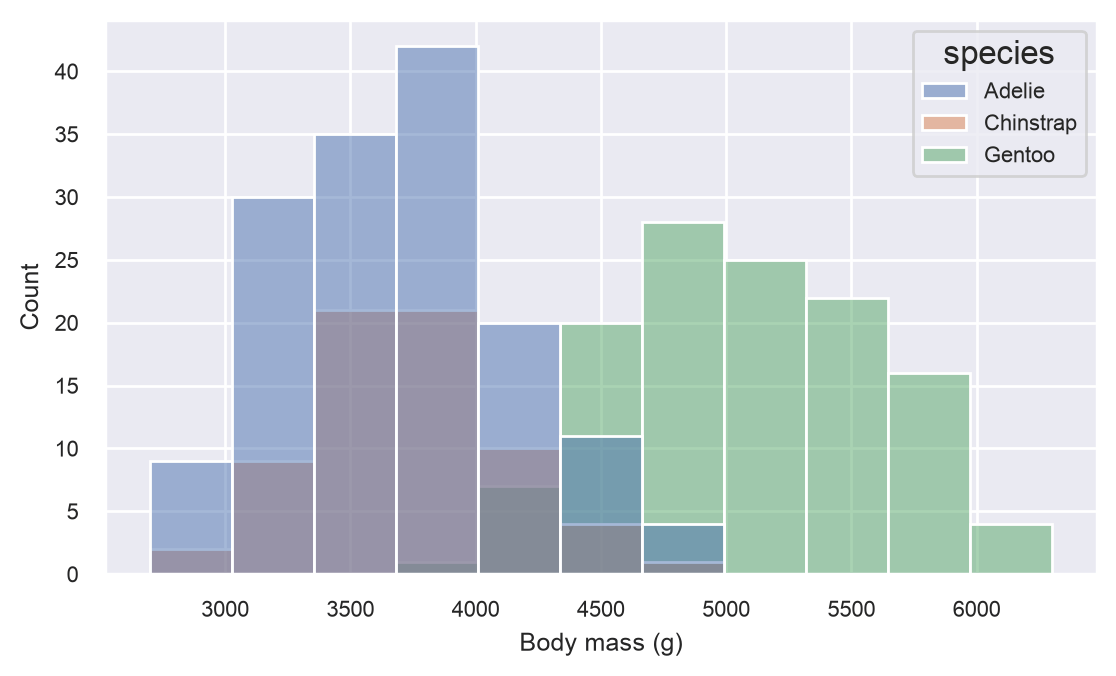

In [1293]:
fig, ax = plt.subplots()
sns.histplot(data=df_penguins, x="body_mass_g", hue="species", ax=ax)
ax.set(xlabel="Body mass (g)");

*See also:* Following an exploration checklist (B5) · Counting missing values (B5) · Describing the whole table (B5) · Drawing a histogram with `histplot` (C3)

#### Checking each step against what is expected

**D6.03**

`assert condition, "message"`

***(non-examinable)***

A step that runs without an error can still be wrong, for example a filter that matches no rows; checking the result of each step against what is expected (a row count, a set of values, a hand calculation) finds the mistake where it happens.

Each check states what the step should have given:

In [1294]:
df_adelie = df_penguins[df_penguins["species"] == "Adelie"]
print(len(df_adelie), "Adelie rows")
assert len(df_adelie) > 0, "no rows matched: check the spelling"
assert set(df_adelie["species"]) == {"Adelie"}

152 Adelie rows


Watch out: with a small spelling mistake the filter runs without an error and keeps no rows. The check stops the analysis at that line:

In [1295]:
df_adelie = df_penguins[df_penguins["species"] == "adelie"]
assert len(df_adelie) > 0, "no rows matched: check the spelling"

AssertionError: no rows matched: check the spelling

*See also:* Checking a DataFrame after each step (B1) · Checking data with `assert` (B1) · Checking a new column against a hand calculation (B1) · Checking a mask before using it (B1)

#### Keeping the raw data unchanged

**D6.04**

`df_clean = df_raw.dropna()`

***(non-examinable)***

Cleaning done in place changes the data that every later step, and every rerun, starts from; keeping the raw table as it was read and cleaning into a new table means each step can be checked against the original.

Watch out: `df_work = df_raw` gives a second name for the same table, so cleaning `df_work` in place also changes `df_raw`:

In [1296]:
df_raw = pd.read_csv("data/penguins.csv")

In [1297]:
df_work = df_raw
df_work.dropna(inplace=True)
print(len(df_raw), "rows left in the raw table")

333 rows left in the raw table


Reading the file again (the file itself was never changed) and cleaning into a new table keeps both:

In [1298]:
df_raw = pd.read_csv("data/penguins.csv")

In [1299]:
# display the first rows of the loaded data
df_raw.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [1300]:
df_clean = df_raw.dropna()
print(f"raw: {len(df_raw)} rows, clean: {len(df_clean)} rows")

raw: 344 rows, clean: 333 rows


*See also:* Removing rows with missing values (B5) · Copying a filtered table (B3) · Checking each step against what is expected (D6)

#### Making an analysis repeatable

**D6.05**

`df.sample(n, random_state=seed)   Kernel > Restart and Run All`

***(non-examinable)***

An analysis is repeatable when running it again gives the same numbers: every random step has a seed, and the notebook gives its results when it is run from the top, not only in the order the cells were written.

With `random_state`, the same sample is drawn every time, so the mean in a report matches the code when it is run again:

In [1301]:
df_sample = df_penguins.sample(20, random_state=1)
print(f"{df_sample['body_mass_g'].mean():.1f} g")
df_sample = df_penguins.sample(20, random_state=1)
print(f"{df_sample['body_mass_g'].mean():.1f} g")

4491.2 g
4491.2 g


Note: without `random_state` (or a seeded `np.random.default_rng(seed)`), each run draws a different sample and gives a different mean.

Note: before handing in a notebook, use **Restart and Run All**. A notebook whose cells were run out of order, or that uses a variable from a deleted cell, may fail or give different numbers.

*See also:* Making random numbers repeatable with a seed (A4) · Estimating a p-value by simulation (D3) · Some principles for scientific data analysis (D6)

### Testing and reporting

#### Deciding the test before seeing the result

**D6.06**

***(non-examinable)***

The test, the alternative hypothesis (one or two sides) and the significance level are chosen from the question before the result is seen; choosing them after looking, or trying tests until one gives p < 0.05, makes a false positive far more likely than the stated 5%.

The choices are written down first, with the reason, and the test then uses them:

In [1302]:
# Decided before the data were analysed
alpha = 0.05
alternative = "two-sided"     # no reason, fixed in advance, to expect one direction

result = stats.ttest_ind(col_chinstrap, col_adelie, equal_var=False,
                         alternative=alternative)
print(f"p = {result.pvalue:.2g}; reject H0 at the {alpha:.0%} level: "
      f"{result.pvalue < alpha}")

p = 6e-08; reject H0 at the 5% level: True


*See also:* Choosing a t-test (D4) · One- or two-sided tests (D4) · False positives (type I error) (D3) · Adjusting p-values for many tests (D4)

#### Reporting the size of an effect, not only p

**D6.07**

`result.confidence_interval(0.95)`

***(non-examinable)***

A p-value says whether a difference is likely to be more than chance, not how large it is, and with enough data a tiny difference gives a small p; a report gives the size of the effect in its units, with a confidence interval for its uncertainty.

The first report gives only p:

In [1303]:
result = stats.ttest_ind(col_chinstrap, col_adelie, equal_var=False)
print(f"p = {result.pvalue:.2g}")

p = 6e-08


The second says how large the difference is, and how precisely it is known (the p-value is then reported with it, as in Reporting a p-value):

In [1304]:
diff = col_chinstrap.mean() - col_adelie.mean()
ci = result.confidence_interval(0.95)
print(f"Chinstrap flippers are {diff:.1f} mm longer than Adelie flippers on average "
      f"(95% CI {ci.low:.1f} to {ci.high:.1f} mm).")

Chinstrap flippers are 5.9 mm longer than Adelie flippers on average (95% CI 3.9 to 7.9 mm).


*See also:* Reporting a t-test (D4) · Confidence intervals (D4) · Cohen's d (D4) · Deciding the test before seeing the result (D6) · Reporting a p-value (D6)

#### Computing numbers instead of typing them

**D6.08**

`f"... {value:.1f} ..."`

***(non-examinable)***

A number typed into the text stays the same when the data or the code change, and can be copied wrongly; a number computed and put into the sentence with an f-string is always the one the code produced.

The first sentence was typed from an earlier run, and nothing connects it to the data:

In [1305]:
print("Gentoo penguins are about 1400 g heavier than Adelie penguins.")

Gentoo penguins are about 1400 g heavier than Adelie penguins.


The second computes the number each time it runs:

In [1306]:
means = df_penguins.groupby("species")["body_mass_g"].mean()
gap = means["Gentoo"] - means["Adelie"]
print(f"Gentoo penguins are {gap:.0f} g heavier than Adelie penguins on average.")

Gentoo penguins are 1375 g heavier than Adelie penguins on average.


*See also:* Reporting a t-test (D4) · Reporting a regression (D5) · Making an analysis repeatable (D6) · Reporting values to a sensible precision (D6)

#### Reporting values to a sensible precision

**D6.10**

`f"{mean:.0f} g (SE {se:.0f} g)"`

***(non-examinable)***

A value in a report is rounded to what the data can support: the uncertainty (a standard error or a confidence interval) is rounded to one or two significant figures, and the estimate to the same decimal place. While working, the full value is printed, so nothing is hidden; the rounding is for the sentence that reports it.

While working, the full values show exactly what was computed:

In [1307]:
col_mass = df_penguins["body_mass_g"].dropna()
mean, se = col_mass.mean(), col_mass.sem()
print(mean, se)

4201.754385964912 43.36473482106863


The standard error is about 40 g, so the digits after the decimal point are noise. In the report, the standard error has two significant figures and the mean is rounded to the same place (whole grams):

In [1308]:
print(f"Mean body mass {mean:.0f} g (standard error {se:.0f} g, n = {len(col_mass)})")

Mean body mass 4202 g (standard error 43 g, n = 342)


Common conventions for a report:

| Value | Reported as | Example |
|---|---|---|
| Uncertainty (SE, CI half-width, sd) | 1 or 2 significant figures | 43 g |
| Estimate (mean, difference, slope) | to the same decimal place as its uncertainty | 4202 g |
| Mean of measured values | at most one digit more than the measurements | 200.9 mm |
| Estimate and its interval | the same number of decimal places | 5.9 mm (95% CI 3.9 to 7.9) |
| t, z, F; r and R² | 2 decimal places | t(df) = 2.41; R² = 0.76 |
| p | 2 significant figures, or "p < 0.001" | p = 0.032 |
| Percentage | a whole number (1 decimal place when small) | 44% |

Watch out: rounding is for display only. A value rounded partway through a calculation passes its rounding error into every later step, so the f-string format code (`:.0f`, `:.2g`) is applied at the end, and `round()` is not used on values that are calculated further.

Note: every reported value has its unit, and a "±" says what it is (a standard deviation, a standard error or a 95% interval).

*See also:* Formatting numbers in an f-string (A1) · Reporting a t-test (D4) · Reporting a p-value (D6) · Computing numbers instead of typing them (D6)

#### Reporting a p-value

**D6.11**

`def format_p(p): ...`

***(non-examinable)***

A common way to report a p-value is to two significant figures, and as "p < 0.001" when it is smaller, because the digits of a very small p carry no extra meaning. It is useful in the sentence of a report; in tutorial code and while working, the exact value is printed so that the result of the test can be seen. Alternatively, `:.2g` alone gives scientific notation for small values (6e-08), which is exact but hard to read in a report.

The exact value is printed while working; the function gives the form for the report:

In [1309]:
def format_p(p):
    """A p-value for a report: 2 significant figures, or p < 0.001."""
    if p < 0.001:
        return "p < 0.001"
    return f"p = {p:.2g}"


result = stats.ttest_ind(col_chinstrap, col_adelie, equal_var=False)
print(result.pvalue)
print(format_p(result.pvalue))
print(format_p(0.0321), format_p(0.4))

6.049266635901903e-08
p < 0.001
p = 0.032 p = 0.4


Note: for a single report line, the same rule fits in one expression, as in Reporting a t-test: `p_text = "p < 0.001" if p < 0.001 else f"p = {p:.2g}"`.

Watch out: `:.4f` turns a very small p into `0.0000`, which reads as "p is zero". A p-value is never zero, so a report writes "p < 0.001" and working code prints the exact value.

*See also:* Reporting values to a sensible precision (D6) · Reporting a t-test (D4) · Deciding whether to reject H0 (D3) · Reporting the size of an effect, not only p (D6)

### Before handing in

#### Checking an analysis before handing it in

**D6.09**

`Kernel > Restart and Run All`

***(non-examinable)***

A checklist of questions, one for each principle of this sheet, to read through before an analysis is handed in or shared, with a last cell that checks the facts the report relies on.

Each "no" points to something to change:
1. Were the size, types, missing values and a plot of the data looked at before any statistic?
2. Is each step checked: a row count, a value worked by hand, an `assert`?
3. Is the raw data unchanged, with cleaning done in a new table?
4. Does every random step have a seed, and does Restart and Run All give the same numbers?
5. Were the test, the sides and the significance level chosen before the result was seen?
6. Does each result give the size of the effect and a confidence interval, not only p?
7. Is every number in the text computed by the code?
8. Is each reported value rounded to its uncertainty, with its unit, and each p given as "p = 0.032" or "p < 0.001"?
9. Does every figure pass the plot checklist (Checking a plot before using it)?

A last cell can check the facts the report relies on, so a change in the data is noticed:

In [1310]:
assert len(df_penguins) == 344, "the data have changed"
assert df_penguins["species"].nunique() == 3, "a species is missing or misspelt"
print("data checks passed")

data checks passed


*See also:* Some principles for scientific data analysis (D6) · Checking a plot before using it (C4) · Reporting a t-test (D4) · Making an analysis repeatable (D6)